In [1]:
import os
import pandas as pd
import librosa
import torch
import numpy as np
import matplotlib.pyplot as plt
from numpy import ndarray
import random
import glob
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
import torchaudio

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## F0 Inconsistency

**Target system:** Concatenative TTS  
**Feature:** F0 trajectory  
**Manipulations:**
- F0 segment shifting  
- F0 segment shuffling


## Define functions

In [61]:
def load_audio(name, file_dir, trim=True, normalize=True, sr=16000, top_db=40):
    path = os.path.join(file_dir, f"{name}.flac")
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)

    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak

    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze() 

def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        last_valid_start_sample = x_len - max_len
        if not last_valid_start_sample == 0:
            start_sample = random.randrange(start=0, stop=last_valid_start_sample)
        else:
            start_sample = 0
        x_pad = x[start_sample: start_sample + max_len]

    else:
        # TEST ON THE MIDDLE WINDOW
        num_windows = round(x_len / max_len)
        if num_windows % 2 == 1:  # odd no. of windows
            middle = num_windows//2
        else:  # even no. of windows
            middle = (num_windows//2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample: start_sample + max_len]

    return x_pad

class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()

    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)

    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()


def extract_f0(waveform,
              fs, win_size, hop_size,
              fmin: int = 70, fmax: int = 400) -> ndarray:

    x = np.copy(waveform)
    x = librosa.effects.preemphasis(x)
    autocorr_win_len = win_size // 2

    f0_freqs, _, _ = librosa.pyin(
        x, sr=fs,
        frame_length=win_size, hop_length=hop_size, center=True,
        win_length=autocorr_win_len, fmin=fmin, fmax=fmax, n_thresholds=7
    )

    return f0_freqs


def flatten_f0(f0_traj, strength=0.9, p=0.5):

    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    f0_ref = np.nanmedian(f0_mod)
    mask = (np.random.rand(len(f0_mod)) < p) & voiced

    f0_mod[mask] = (
            (1.0 - strength) * f0_mod[mask]
            + strength * f0_ref
    )

    return f0_mod


def f0_segment_shift(f0_traj, seg_len_s, hop_s, p_seg):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)
    i = 0

    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue

        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes, shift some
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)

            if np.random.rand() < p_seg:
                shift = random.choice([
                    random.uniform(0.895, 0.945),
                    random.uniform(1.065, 1.15)
                ])
                f0_mod[j:seg_j_end] *= shift

            j = seg_j_end

    return f0_mod


def f0_segment_shuffle(f0_traj, seg_len_s, hop_s, p_shuffle):
    f0_mod = f0_traj.copy()
    voiced = ~np.isnan(f0_mod)

    seg_len_frames = int(seg_len_s / hop_s)

    segments = []
    indices = []

    i = 0
    while i < len(f0_mod):
        if not voiced[i]:
            i += 1
            continue
        
        # find voiced segment f0_mod[seg_start : seg_end]
        seg_start = i
        while i < len(f0_mod) and voiced[i]:
            i += 1
        seg_end = i

        # chunk the voiced segment in pseudo-phonemes    
        j = seg_start
        while j < seg_end:
            seg_j_end = min(j + seg_len_frames, seg_end)
            
            segments.append(f0_mod[j:seg_j_end].copy())
            indices.append((j, seg_j_end))
            j = seg_j_end

    if len(segments) < 2:
        return f0_mod

    # partial shuffle
    perm = list(range(len(segments)))
    for i in range(len(perm)):
        if random.random() < p_shuffle:
            j = random.randrange(len(perm))
            perm[i], perm[j] = perm[j], perm[i]

    # re-insert
    for out_i, src_i in enumerate(perm):
        start, end = indices[out_i]
        seg = segments[src_i]
        L = min(end - start, len(seg))
        f0_mod[start:start+L] = seg[:L]

    return f0_mod


def apply_f0_mod(f0_traj, mod='shift', hop_s=0.016):
    
    if mod == 'shift':
        seg_len = random.uniform(0.08, 0.16)  # 80–160 ms
        p_seg = random.uniform(0.4, 0.7)

        f0_traj_mod = f0_segment_shift(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_seg=p_seg
        )
        
    elif mod == 'shuff':
        seg_len = random.uniform(0.08, 0.16)
        p_shuffle = random.uniform(0.1, 0.3)

        f0_traj_mod = f0_segment_shuffle(
            f0_traj,
            seg_len_s=seg_len,
            hop_s=hop_s,
            p_shuffle=p_shuffle
        )

    elif mod == 'flat':
        f0_traj_mod = flatten_f0(f0_traj, 
                                 strength=0.6, 
                                 p=1)
        
    else:
        f0_traj_mod = None
        print(f"Manipulation not recognized.")
        
    return f0_traj_mod
    

## Load base tracks

## Extract F0 and apply manipulation

In [7]:
mod = 'flat'
fs = 16000
stft_params = STFTWindowParams()

In [62]:
df_real = pd.read_pickle("pickles/F0_Inconsistency_DF_R.pkl")

nan_count = 0
for idx, row in tqdm(df_real.iterrows(), total=len(df_real)):
    f0_traj = row["f0_traj"]

    if np.all(np.isnan(f0_traj)):
        f0_traj_mod = None
        nan_count += 1
    else:
        f0_traj_mod = apply_f0_mod(
            f0_traj,
            mod=mod,
            hop_s=stft_params.hop_sec
        )

    df_real.at[idx, "f0_traj_mod"] = f0_traj_mod

print(f"{nan_count}/{len(df_real)} tracks have all-NaN F0 trajectories")

df_real.to_pickle("pickles/F0_Inconsistency_DF_R.pkl")
df_real
  

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2580/2580 [00:01<00:00, 1849.14it/s]


102/2580 tracks have all-NaN F0 trajectories


,name,f0_traj,f0_traj_mod
0,LA_T_1138215,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
1,LA_T_1271820,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2,LA_T_1272637,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
3,LA_T_1276960,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
4,LA_T_1341447,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
...,...,...,...
2575,LA_T_9387015,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2576,LA_T_9497115,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2577,LA_T_9557645,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."
2578,LA_T_9737995,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ..."


## Visual inspection

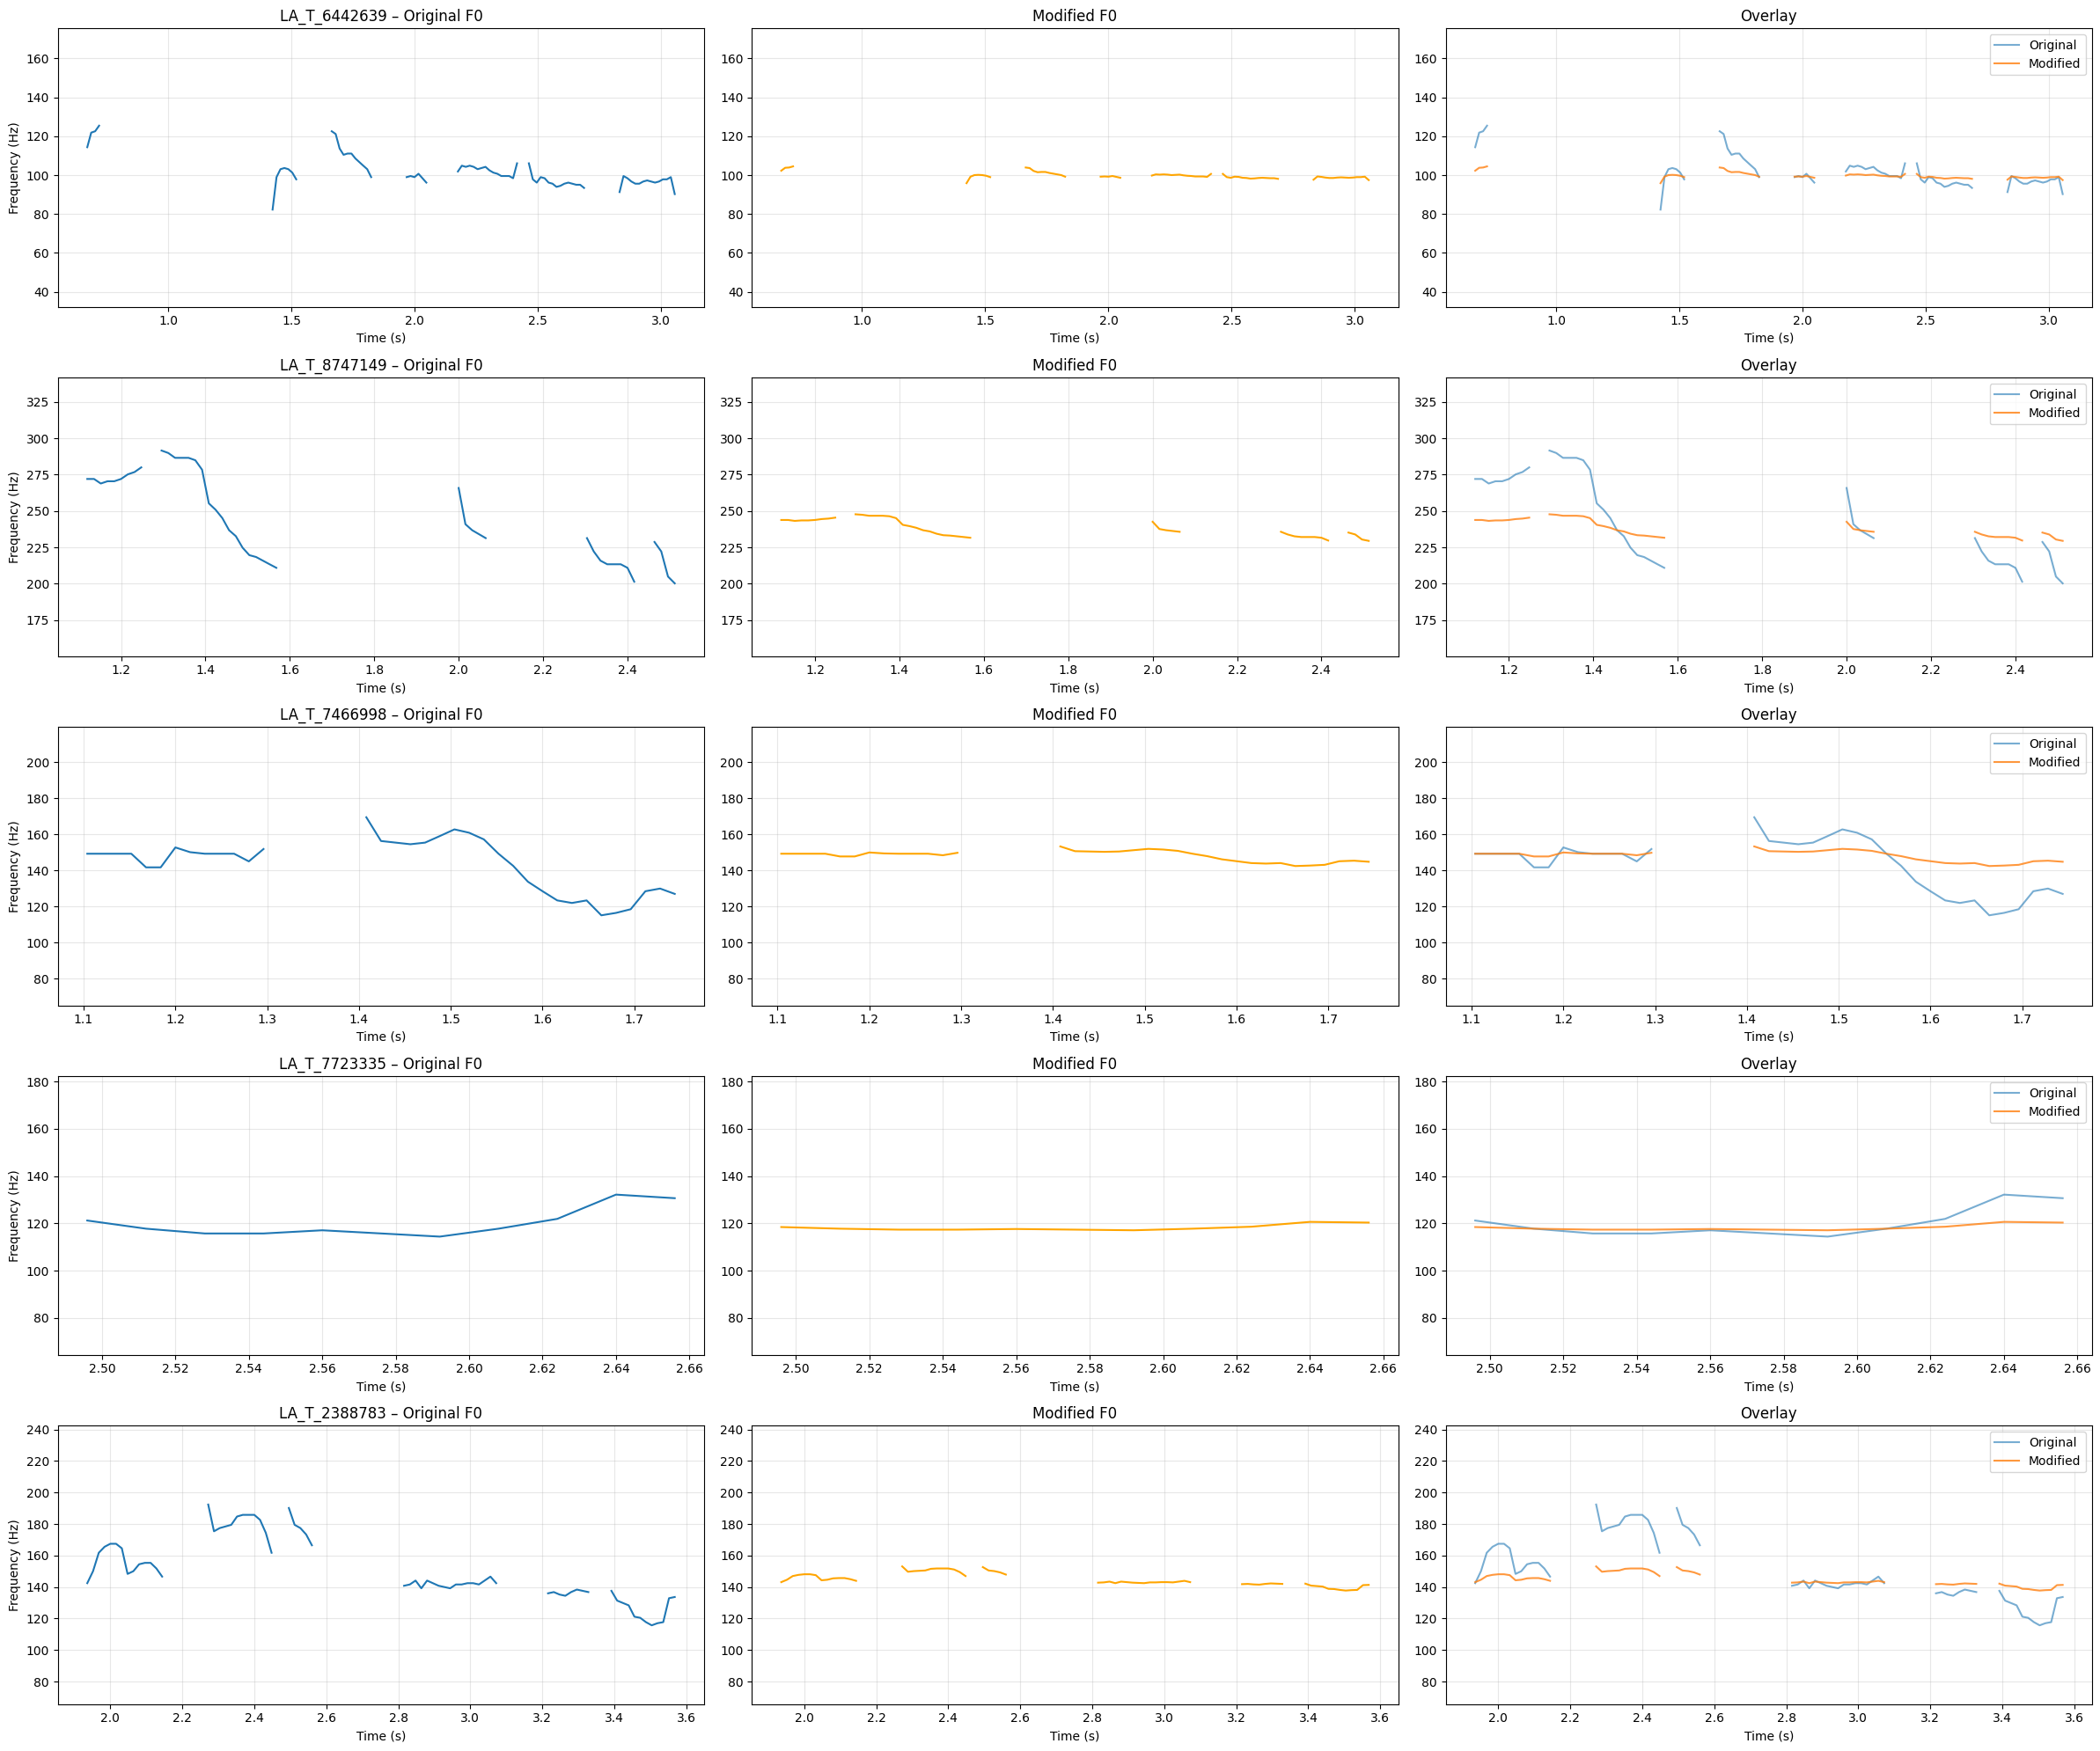

In [16]:
df_valid = (
    df_real[df_real['f0_traj_mod'].notnull()]
    .sample(n=5, random_state=42)
    .reset_index(drop=True)
)

n_tracks = len(df_valid)

fig, axes = plt.subplots(
    n_tracks, 3,
    figsize=(24, 4 * n_tracks),
    sharex=False
)

if n_tracks == 1:
    axes = axes[np.newaxis, :]

for i, row in df_valid.iterrows():
    f0 = row["f0_traj"]
    f0_mod = row["f0_traj_mod"]

    n_frames = len(f0)
    time = np.arange(n_frames) * (stft_params.hop_size / stft_params.sample_rate)

    valid = np.isfinite(f0)
    f0_min = np.nanmin(f0[valid])
    f0_max = np.nanmax(f0[valid])
    pad = 50  # Hz

    # Original
    axes[i, 0].plot(time, f0)
    axes[i, 0].set_title(f"{row['name']} – Original F0")
    axes[i, 0].set_ylabel("Frequency (Hz)")
    axes[i, 0].set_ylim(f0_min - pad, f0_max + pad)

    # Modified
    axes[i, 1].plot(time, f0_mod, color='orange')
    axes[i, 1].set_title("Modified F0")
    axes[i, 1].set_ylim(f0_min - pad, f0_max + pad)

    # Overlay
    axes[i, 2].plot(time, f0, label="Original", alpha=0.6)
    axes[i, 2].plot(time, f0_mod, label="Modified", alpha=0.8)
    axes[i, 2].set_title("Overlay")
    axes[i, 2].set_ylim(f0_min - pad, f0_max + pad)
    axes[i, 2].legend()

    for j in range(3):
        axes[i, j].set_xlabel("Time (s)")
        axes[i, j].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## Load Tracks from ASVspoof 2019

In [72]:
algorithm = 'A02'

p = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt'
f = '/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_train/flac'

df_all = pd.read_csv(p, sep=' ', header=None)

In [73]:
df_concat_tts = (
    df_all[df_all[3] == 'A02']
    .assign(path=lambda df_all: df_all[1].apply(
        lambda x: os.path.join(f, f"{x}.flac")
    ))[['path']]
)
fake_list = df_concat_tts['path'].tolist()
print(len(fake_list))

3800


In [74]:
rows = []
nan_count = 0
total = len(fake_list)

for i in tqdm(fake_list, total=len(fake_list)):
    name = os.path.splitext(i)[0]
    x = load_audio(name, file_dir=f)
    
    f0_traj = extract_f0(
        x,
        fs=stft_params.sample_rate,
        win_size=stft_params.win_size,
        hop_size=stft_params.hop_size
    )
    
    if np.all(np.isnan(f0_traj)):
        nan_count += 1
        
    rows.append({
        "name": os.path.splitext(os.path.basename(name))[0],
        "f0_traj": f0_traj,
    })

print(f"{nan_count}/{total} tracks have all-NaN F0 trajectories")

df_fake = pd.DataFrame(rows)
df_fake.to_pickle("pickles/F0_Inconsistency_DF_F_A02.pkl")

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 3800/3800 [30:52<00:00,  2.05it/s]


50/3800 tracks have all-NaN F0 trajectories
